# Olist — pré-processamento, treinamento e avaliação (TASK 02)

Notebook de consulta executado após as decisões seladas. **Não dispara treinamento nem busca.** Para reproduzir o protocolo, consulte `docs/README_task02.md`.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/olist_modeling").is_dir())
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), "Selecione Python (Olist .venv)"
TABLES = ROOT / "resultados/tabelas/task02"
FIGURES = ROOT / "resultados/graficos/task02"
read_json = lambda name: json.loads((TABLES / name).read_text(encoding="utf-8"))
print("Ambiente:", sys.version.split()[0], "| kernel Olist local")

Ambiente: 3.13.6 | kernel Olist local


## Pré-processamento e orçamento

Mediana numérica, categoria ausente explícita, one-hot e seleção de constantes dentro de Pipeline/ColumnTransformer. Ridge: escala robusta; árvores: sem escala. Extremos válidos preservados. GridSearchCV em uma divisão cronológica, sem refit automático sobre validação; MAE define escolha, sementes 42.

In [2]:
protocol = read_json("protocol.json")
frozen = read_json("selection_frozen.json")
print("Configurações pesquisadas:", protocol["candidate_count"])
print("Escolha congelada:", frozen["selected_model"])
print("Parâmetros por modelo:", frozen["all_best_params"])
display(pd.read_csv(TABLES / "split_summary.csv"))
display(pd.read_csv(TABLES / "search_candidates.csv"))

Configurações pesquisadas: 14
Escolha congelada: Ridge
Parâmetros por modelo: {'Baseline': {'strategy': 'median'}, 'DecisionTree': {'model__estimator__max_depth': 10, 'model__estimator__min_samples_leaf': 20}, 'RandomForest': {'model__estimator__max_features': 1.0, 'model__estimator__min_samples_leaf': 40}, 'Ridge': {'model__estimator__alpha': 1.0}}


,split,rows,cohort_pct,purchase_min,purchase_max,delivery_max,label_cutoff_exclusive
0,train_candidates,67379,69.844511,2016-09-15 12:16:38,2018-04-14 23:28:11,2018-09-19 23:24:07,2018-04-15 00:00:00
1,train,64401,66.757541,2016-09-15 12:16:38,2018-04-13 13:01:55,2018-04-14 22:04:08,2018-04-15 00:00:00
2,validation_candidates,14606,15.140458,2018-04-15 00:08:41,2018-06-20 23:39:24,2018-10-17 13:22:46,2018-06-21 00:00:00
3,validation,12675,13.138800,2018-04-15 00:08:41,2018-06-19 13:09:39,2018-06-20 23:58:37,2018-06-21 00:00:00
4,test,14485,15.015031,2018-06-21 00:22:02,2018-08-29 15:00:37,2018-10-02 00:18:50,snapshot final; data de extração desconhecida
5,final_train,80043,82.971908,2016-09-15 12:16:38,2018-06-19 13:09:39,2018-06-20 23:58:37,2018-06-21 00:00:00


,model,params,MAE_days,RMSE_days,R2,mean_fit_seconds,selected_within_model
0,Ridge,"{""model__estimator__alpha"": 0.1}",4.259881,5.751997,0.321977,0.647669,False
1,Ridge,"{""model__estimator__alpha"": 1.0}",4.259612,5.751332,0.322133,0.631314,True
2,Ridge,"{""model__estimator__alpha"": 10.0}",4.259684,5.749257,0.322623,0.515756,False
3,Ridge,"{""model__estimator__alpha"": 100.0}",4.272179,5.747210,0.323105,0.416833,False
4,DecisionTree,"{""model__estimator__max_depth"": 6, ""model__est...",4.682672,5.991105,0.264435,0.771716,False
5,DecisionTree,"{""model__estimator__max_depth"": 6, ""model__est...",4.687343,5.986884,0.265471,0.730916,False
6,DecisionTree,"{""model__estimator__max_depth"": 10, ""model__es...",4.397203,5.863938,0.295330,1.573482,True
7,DecisionTree,"{""model__estimator__max_depth"": 10, ""model__es...",4.415409,5.837275,0.301723,1.487176,False
8,DecisionTree,"{""model__estimator__max_depth"": 14, ""model__es...",4.465655,6.038333,0.252792,3.339149,False
9,DecisionTree,"{""model__estimator__max_depth"": 14, ""model__es...",4.411723,5.866508,0.294712,2.393827,False


## Escolha na validação e avaliação final única

A seleção foi selada antes de abrir o teste. O vencedor e a referência foram reajustados somente com rótulos conhecidos antes do teste. Comparação de teste abaixo é consulta dos resultados registrados; não altera a escolha.

,model,MAE_days,RMSE_days,R2,fit_seconds,best_params,candidates
0,Ridge,4.259612,5.751332,0.322133,3.077965,"{""model__estimator__alpha"": 1.0}",4
1,RandomForest,4.283710,5.699135,0.334382,382.691089,"{""model__estimator__max_features"": 1.0, ""model...",4
2,DecisionTree,4.397203,5.863938,0.295330,12.332762,"{""model__estimator__max_depth"": 10, ""model__es...",6
3,Baseline,5.455450,7.040165,-0.015718,0.017325,"{""strategy"": ""median""}",1


,role,model,MAE_days,RMSE_days,R2
0,selected,Ridge,4.108062,5.527860,-0.024625
1,baseline_reference,Baseline,4.825818,6.079617,-0.239377


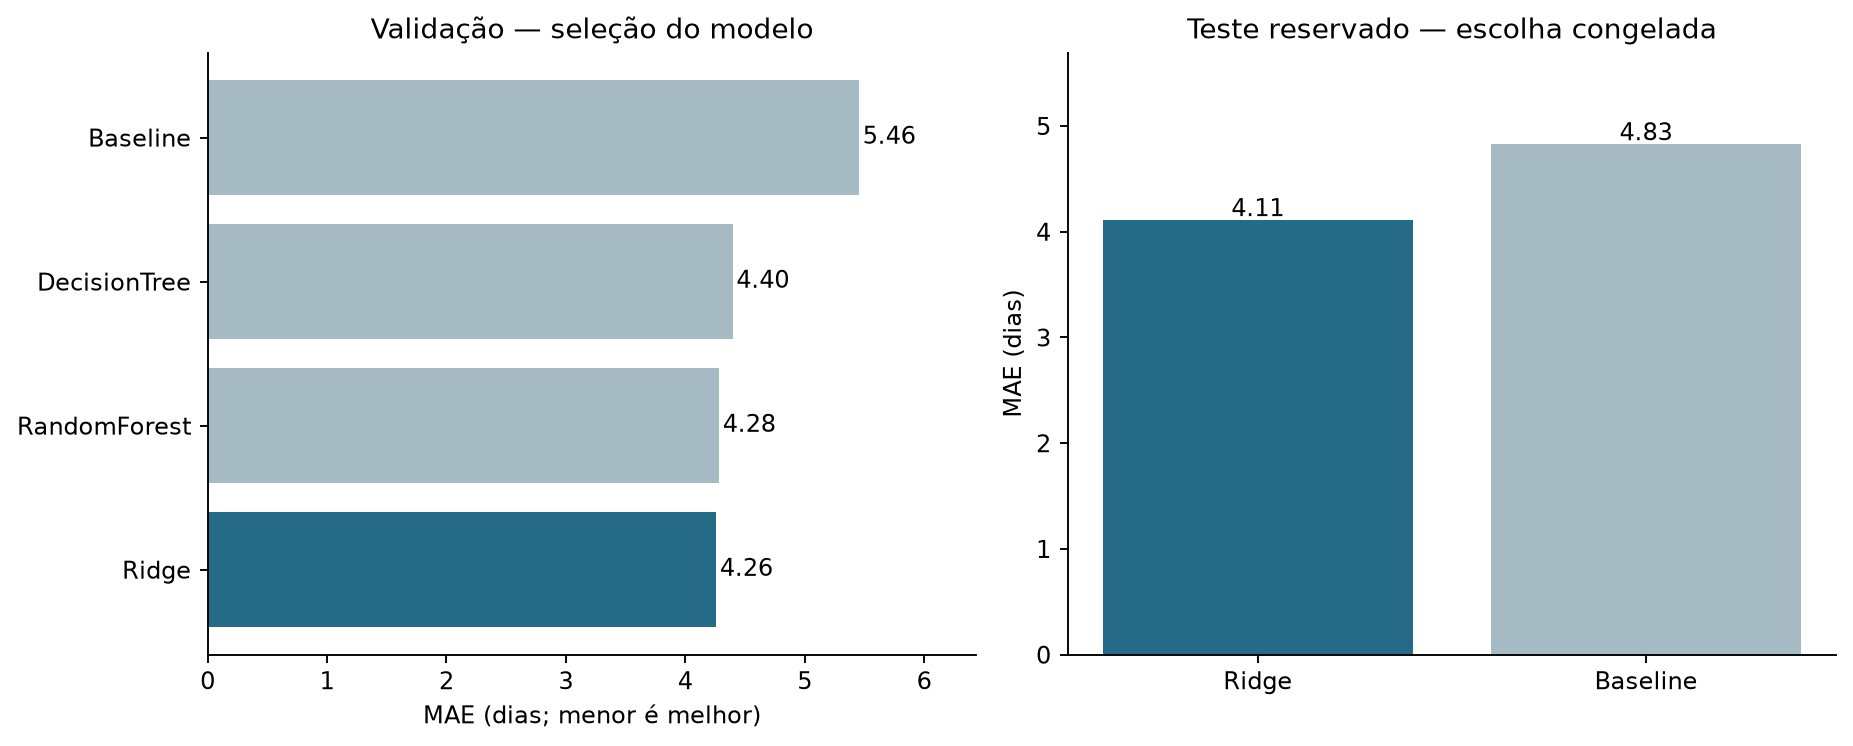

In [3]:
from olist_features.audit import sha256
opening = read_json("test_evaluation_started.json")
assert frozen["sealed_at_utc"] < opening["started_at_utc"]
assert opening["selection_sha256"] == sha256(TABLES / "selection_frozen.json")
display(pd.read_csv(TABLES / "validation_metrics.csv"))
display(pd.read_csv(TABLES / "test_metrics.csv"))
display(Image(filename=str(FIGURES / "07_model_comparison.png"), width=1000))

## Resíduos e maiores falhas

MAE/RMSE em dias; resíduos positivos significam subestimação. Métricas foram conferidas independentemente. Falhas por faixa do alvo são diagnóstico posterior, não features. Esta inspeção não gerou ajuste adicional no teste.

{'mae_improvement_over_baseline_pct': 14.87325594400124, 'mean_residual_days': -2.1472920289801714, 'median_absolute_error_days': 3.334092638427438, 'negative_predictions': 0, 'p90_absolute_error_days': 8.232065759978672, 'p95_absolute_error_days': 9.87547007158833, 'rows': 14485, 'test_evaluation_events': 1, 'within_3_days_pct': 45.447014152571626, 'within_5_days_pct': 68.65723161891611}


,order_id,purchase_timestamp,customer_state,items_count,sellers_count,items_missing_distance_count,actual_days,predicted_days,baseline_days,residual_days,absolute_error_days
0,7797e37c568b84182c813b9b2492b384,2018-06-25 16:44:38,SP,1,1,0,78.963206,8.300872,11.039213,70.662334,70.662334
1,0096668e5b0b8e9657a6f7209a4e58b4,2018-07-11 13:33:21,SP,1,1,0,68.048206,5.934791,11.039213,62.113415,62.113415
2,4530ebf341c28451b56c66fc4d70f8eb,2018-06-21 17:27:55,BA,1,1,0,76.027025,16.175892,11.039213,59.851134,59.851134
3,f23681a0fffdb8051c674707c7e912ef,2018-07-15 02:11:15,RS,1,1,0,68.899468,13.139682,11.039213,55.759786,55.759786
4,ae213a9f84c777fb7a31e8c0f09fd30c,2018-07-03 22:13:48,AL,1,1,0,77.731146,23.949355,11.039213,53.781791,53.781791
5,a2b4be96b53022618030c17ed437604d,2018-07-22 09:54:03,PE,1,1,0,66.687847,16.637066,11.039213,50.050781,50.050781
6,b2997e1d7061605e9285496c581d1fbd,2018-07-30 09:08:06,MG,1,1,0,63.632454,13.986331,11.039213,49.646122,49.646122
7,6325af88a0611fc357055cb87dcec11e,2018-07-18 13:40:31,MG,1,1,0,61.005521,12.121787,11.039213,48.883734,48.883734
8,c83bfcbbc1e49ea80f7a77732efa3d48,2018-06-27 22:09:27,RS,1,1,0,60.741667,12.761799,11.039213,47.979868,47.979868
9,84db939b1ab9686533e9a06a0354beb6,2018-07-20 13:14:25,SP,1,1,0,59.024062,11.227949,11.039213,47.796113,47.796113


,actual_range_days,orders,mean_actual,mean_predicted,MAE_days
0,"[0.0, 5.0)",3518,3.345883,6.635579,3.337602
1,"[10.0, 20.0)",3465,13.038001,13.756446,4.011980
2,"[20.0, 40.0)",472,24.903552,16.027656,9.278618
3,"[40.0, inf)",38,53.385131,13.968140,39.416991
4,"[5.0, 10.0)",6992,7.218297,10.468902,4.002392


,purchase_month,orders,MAE_days,RMSE_days,R2
0,2018-06,1978,3.906465,5.764368,0.074851
1,2018-07,6156,4.500729,6.069830,0.041831
2,2018-08,6351,3.790238,4.861362,-0.256543


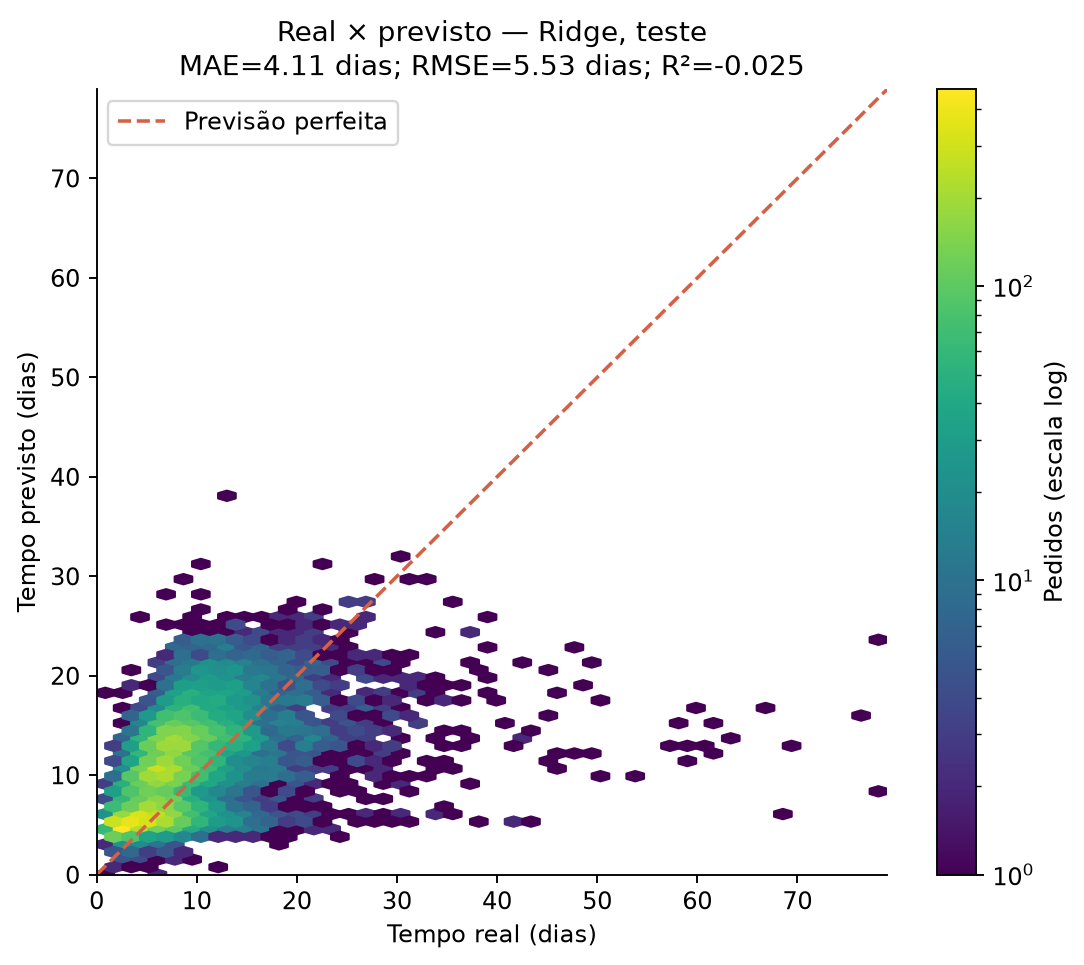

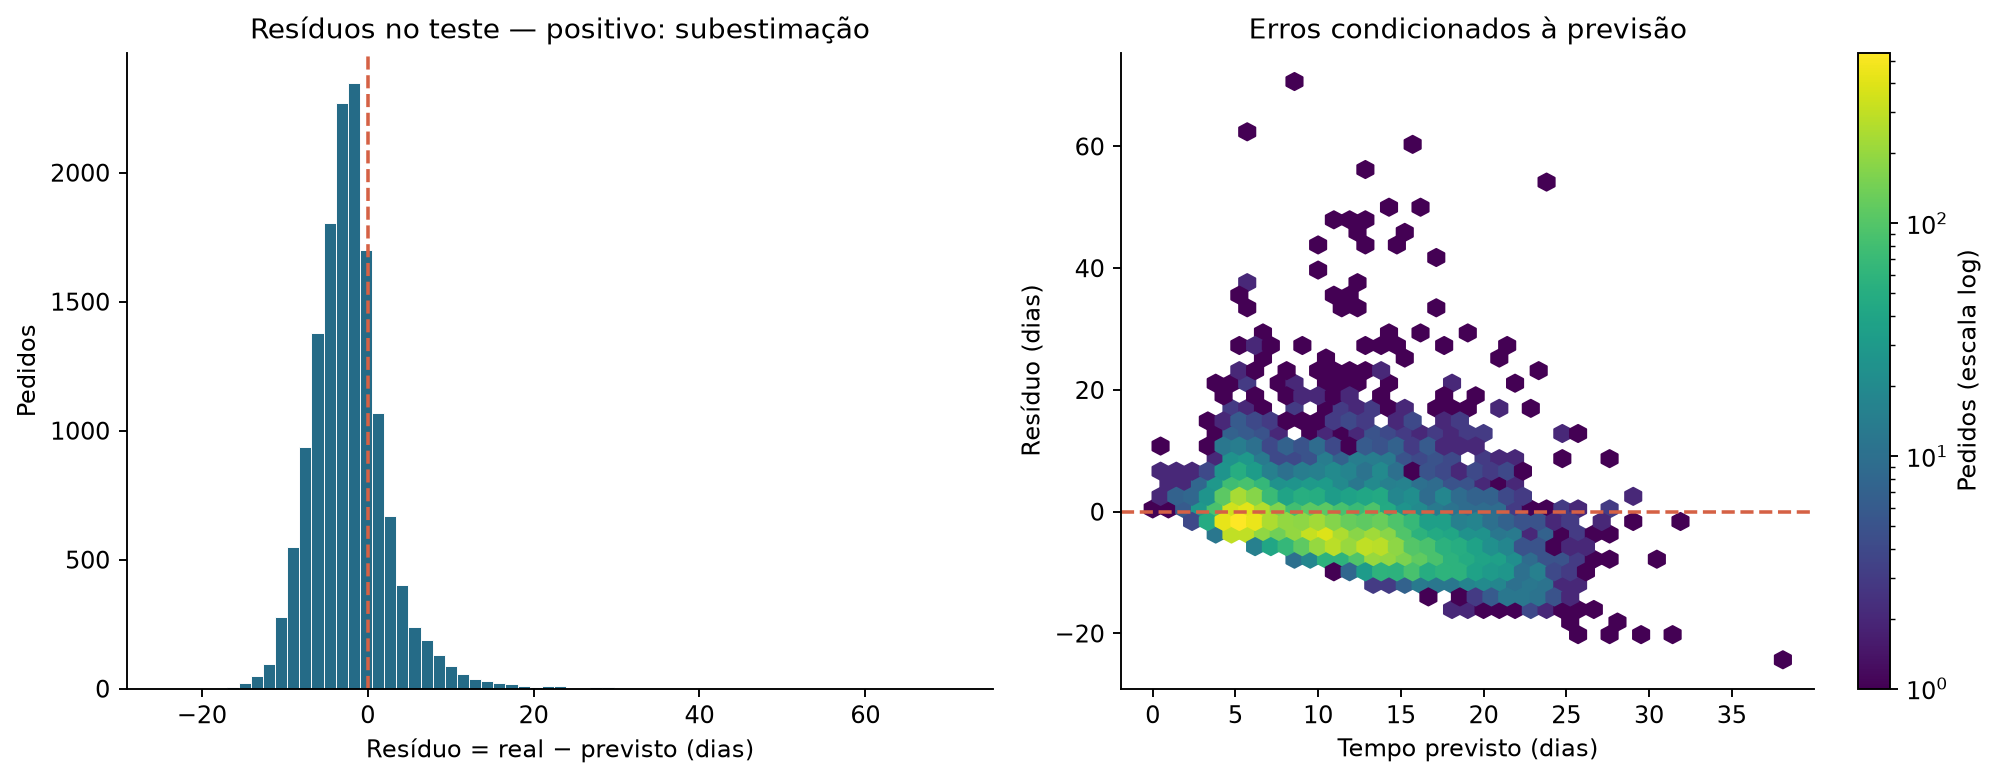

In [4]:
print(read_json("test_diagnostics.json"))
display(pd.read_csv(TABLES / "largest_test_errors.csv").head(10))
display(pd.read_csv(TABLES / "test_errors_by_actual_range.csv"))
display(pd.read_csv(TABLES / "test_errors_by_month.csv"))
display(Image(filename=str(FIGURES / "08_actual_predicted_test.png"), width=850))
display(Image(filename=str(FIGURES / "09_residuals_test.png"), width=1050))

## Importância e verificação

Permutação na validação, após selar a escolha, mede sensibilidade preditiva. Correlação pode mascarar a importância. Não há interpretação causal. Refits técnicos mantêm os parâmetros e verificam previsões, sem retunar a partir do teste.

,feature,increase_MAE_days_mean,std
0,distance_km_min,0.922279,0.044577
1,same_state_items_fraction,0.311821,0.030008
2,customer_state,0.310691,0.017202
3,main_category,0.127880,0.026420
4,distance_km_mean,0.065037,0.006053
5,purchase_weekday,0.040360,0.003606
6,sellers_count,0.030658,0.001974
7,volume_cm3_total,0.022121,0.003081
8,height_cm_max,0.022022,0.005271
9,items_count,0.019743,0.002560


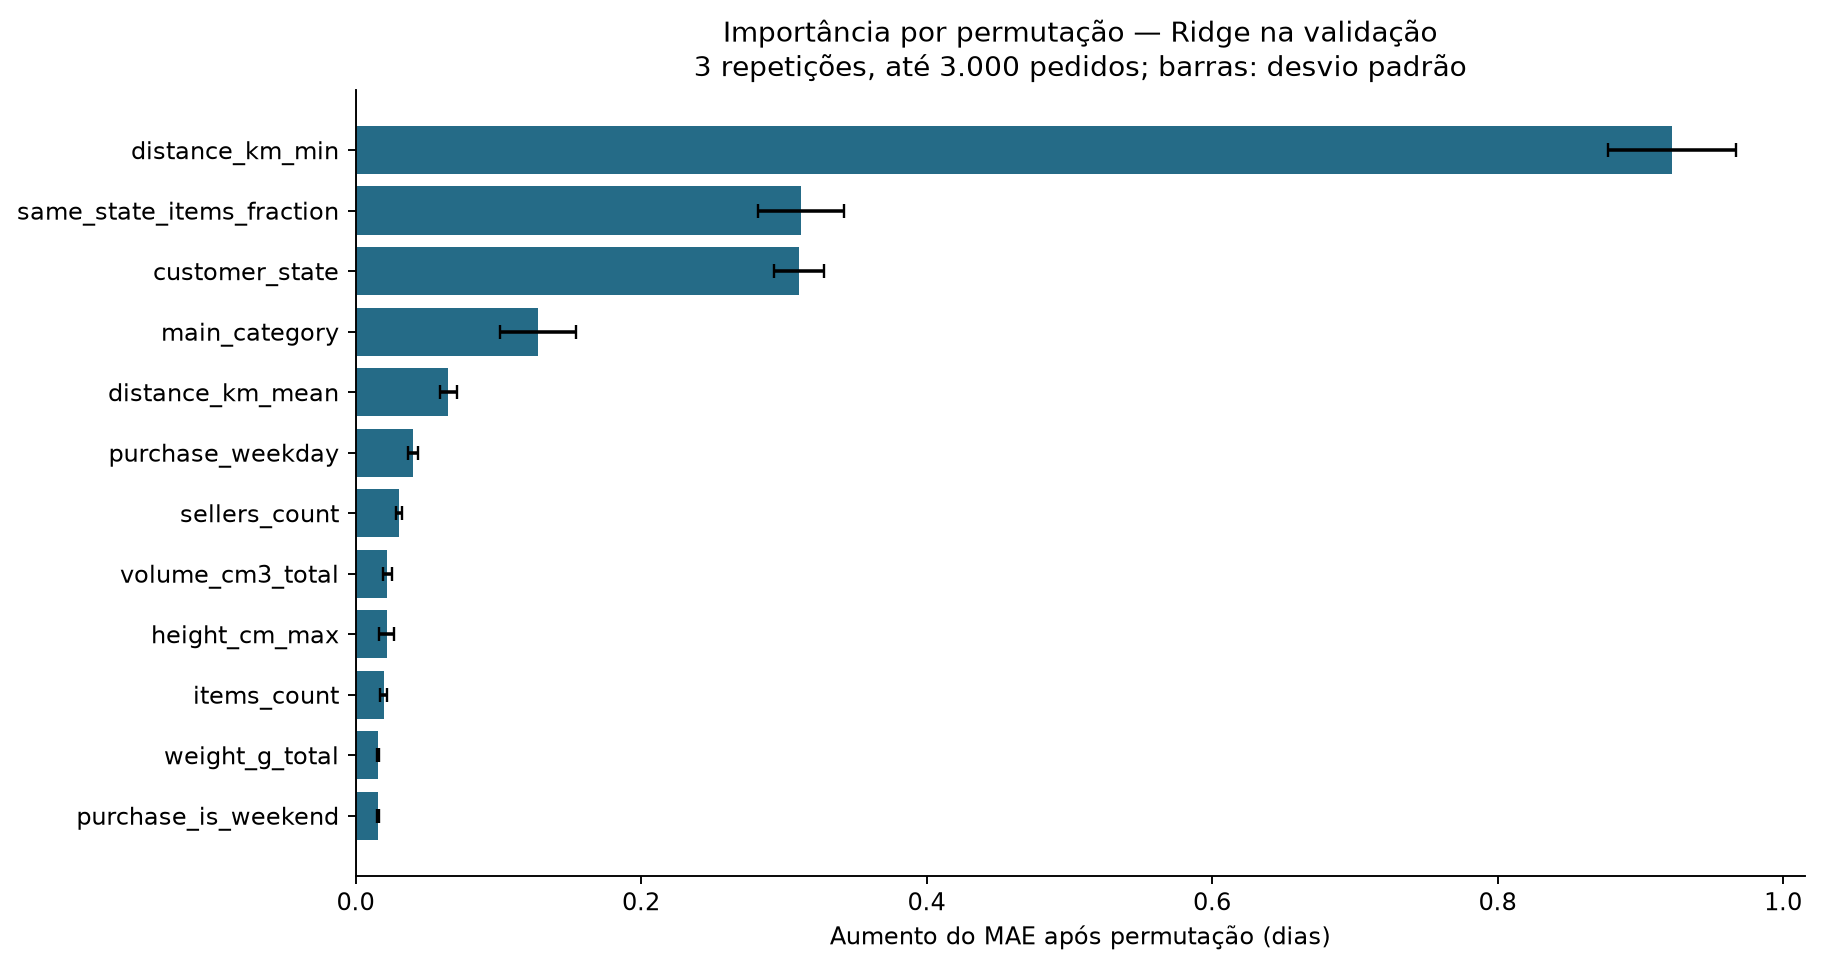

{'checks': 77, 'full_data_refits': True, 'passed': True, 'refit_prediction_tolerance_days': 1e-09, 'task01_files_preserved': 47, 'test_evaluation_events': 1, 'test_selection_repeated': False}


,stage,model,rows_fit,max_abs_prediction_delta,elapsed_seconds,passed
0,validation,Baseline,64401,0.000000e+00,0.006096,True
1,validation,DecisionTree,64401,0.000000e+00,1.745235,True
2,validation,RandomForest,64401,7.105427e-15,85.777826,True
3,validation,Ridge,64401,0.000000e+00,0.762383,True
4,final_inference,Ridge,80043,0.000000e+00,1.102537,True


Verificações aprovadas: 77


In [5]:
importance = TABLES / "importance_validation_permutation.csv"
if importance.exists():
    display(pd.read_csv(importance))
    display(Image(filename=str(FIGURES / "10_importance_validation.png"), width=1000))
print(read_json("verification_summary.json"))
display(pd.read_csv(TABLES / "reproducibility_refits.csv"))
checks = pd.read_csv(TABLES / "verification_checks.csv")
assert checks.passed.all()
print("Verificações aprovadas:", len(checks))

## Modelo salvo e limites

`resultados/modelos/task02/final_model.joblib` contém o pipeline, e `inference_contract.json` define as 30 entradas. A amostra é condicionada à entrega; maturação, censura, snapshot sem histórico, CEPs aproximados e uma única janela limitam a generalização. Não há intervalos calibrados ou garantia operacional. Próximas decisões estão em `docs/treinamento_avaliacao.md`.